# Hands-On Session 2: Building out your first RAG
## Topics:
**Lab 2-A: Build and inspect**

1. Understanding the data, including the pages a parser gets wrong
2. Experiment with different chunking strategies
3. Creating our vector database

**Lab 2-B: Evaluate**

4. Measure it against a golden question set

**Lab 2-C: Make your own test questions**

5. Generate questions from the hard pages, review them, and hold some out

**Dataset: Behr technical data sheets.** 137 technical data sheets for BEHR paints, primers and stains.

<!-- twin: dataset-specific -->

**Goal.** After this lab you can build a naive RAG pipeline end to end, find the pages its parser gets wrong, score the pipeline against a golden question set, and build and review a small test set of your own.

In [ ]:
#@title #Installs, Imports and Global Variables
%%capture
%pip install ipython-autotime
%load_ext autotime
# Every version here is pinned on purpose. An unpinned dependency is a bet that nothing
# upstream changes between now and the moment you run this, and that bet is how a notebook
# that worked last week stops working today.
%pip install -q \
  litellm==1.102.0 "openai>=2.20.0,<3.0.0" \
  llama-index==0.14.24 llama-index-readers-file==0.7.0 fonttools==4.65.0 \
  llama-index-vector-stores-chroma==0.6.0 \
  llama-index-embeddings-litellm==0.6.0 llama-index-llms-litellm==0.8.0 \
  chromadb==1.5.9 pypdf==6.19.0 pymupdf==1.28.2 \
  llama-index-retrievers-bm25==0.8.0 bm25s==0.3.14 PyStemmer==2.2.0.3 \
  ipywidgets==7.7.1 pandas==2.2.3 \
  ragas==0.4.3 "langchain-community==0.3.27" "langchain-core<0.4" "langchain-openai<1" datasets==5.0.1

In [ ]:
#@title Imports
import os
import random
import pymupdf  # PyMuPDF
pymupdf.no_recommend_layout()  # silences advice to install pymupdf_layout, a package this lab does not use
import io
import pickle
import json
import zipfile
import concurrent.futures

import numpy as np
import pandas as pd

from PIL import Image
from litellm import completion
from llama_index.core import SimpleDirectoryReader
from llama_index.core.ingestion import IngestionPipeline
from llama_index.core.node_parser import SentenceSplitter

# ragas warns about its own API changes on import; the warnings say nothing about your run.
# The filter has to be in place before the import it is meant to quiet.
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

from datasets import Dataset

from ragas import evaluate
from ragas.metrics import (
    answer_relevancy,
    faithfulness,
    context_recall,
    context_precision,
)
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

import litellm

litellm.drop_params = True

# Dollar amounts in the answers and contexts would otherwise be typeset as maths in table output.
pd.set_option("display.html.use_mathjax", False)
# Keep the model libraries quiet. At the default level they log every call, and a wall of INFO lines
# buries the one result you are looking for.
import logging
logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("LiteLLM").setLevel(logging.WARNING)

In [ ]:
# twin: dataset-specific
# Your OpenRouter key. One key covers every model call in this notebook: chat,
# embeddings and the evaluation judge all go through OpenRouter.
#
# Get a key at https://openrouter.ai/keys. Then either add it to Colab's Secrets
# panel (the key icon in the left sidebar) under the name OPENROUTER_API_KEY and
# switch on notebook access, or paste it when this cell asks. On the workshop day
# the hub handed one out instead, and it still will if a workshop is running.
import json, os, urllib.error, urllib.request
from getpass import getpass

WORKSHOP_HUB = "https://tdwi-workshop-hub.vercel.app"

def load_openrouter_key(hub=WORKSHOP_HUB):
    """Find a key and load it into this session. Says where it came from, never what it is."""
    if os.environ.get("OPENROUTER_API_KEY"):
        return "this session"
    try:
        from google.colab import userdata
        key = userdata.get("OPENROUTER_API_KEY")
        if key:
            os.environ["OPENROUTER_API_KEY"] = key.strip()
            return "Colab Secrets"
    except Exception:
        pass  # not in Colab, no secret by that name, or notebook access is switched off
    try:
        request = urllib.request.Request(
            f"{hub}/api/env", data=b"{}", headers={"content-type": "application/json"})
        with urllib.request.urlopen(request, timeout=20) as response:
            os.environ.update(json.load(response))
        return "the workshop hub"
    except Exception:
        pass  # the hub only hands out keys while a workshop is running
    key = getpass("Paste your OpenRouter API key (get one at https://openrouter.ai/keys): ").strip()
    if not key:
        raise SystemExit(
            "No key was pasted, so nothing in this notebook can call a model. Get one at "
            "https://openrouter.ai/keys, then run this cell again.")
    os.environ["OPENROUTER_API_KEY"] = key
    return "the key you pasted"

print("OpenRouter key loaded from", load_openrouter_key())

# Shared settings, fetched rather than retyped. Every lab reads the same file, so the chunk
# size here and the chunk size in Lab 3 cannot drift apart.
import json as _json, urllib.request as _urllib

DATASET = 'behr'   # one notebook per dataset, on purpose; no picker here
_CONFIG_URL = "https://raw.githubusercontent.com/ndecavel/tdwi-workshop-labs/60715aaea632ef427e03ac963ef7c29f69769a06/data/dataset_config.json"
_urllib.urlretrieve(_CONFIG_URL, "/content/dataset_config.json")
CFG = _json.load(open("/content/dataset_config.json"))
SHARED, DS = CFG['shared'], CFG['datasets'][DATASET]


MODEL = SHARED['litellm_chat_model']      # LiteLLM form, needs the openrouter/ prefix
EMBED_MODEL = SHARED['embed_model']

# Query-time embeddings must use the same model that built the index. A different one
# does not raise, it just quietly retrieves worse.

# Chunking comes from the dataset, not from this cell, so that what you build here matches
# the corpus Lab 3 downloads and the chunk sizes the workshop hub's explorer shows. Behr is
# 1024/200; CalHR is 384/96 because it is a sixth the size and needs finer chunks before
# retrieval has anything to discriminate on.
CHUNK_SIZE = DS['chunk_size']
CHUNK_OVERLAP = DS['chunk_overlap']
print(f"chunking at {CHUNK_SIZE}/{CHUNK_OVERLAP} for {DS['label']}")

DOCS_FOLDER_PATH = "/content/downloaded_pdfs/"

### Source documents for this dataset.
### Download TDS documents from github
!wget https://raw.githubusercontent.com/ndecavel/tdwi-workshop-labs/60715aaea632ef427e03ac963ef7c29f69769a06/data/behr/Data_Resources_TDS.zip

# !unzip /content/Data_Resources_TDS.zip
with zipfile.ZipFile('/content/Data_Resources_TDS.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

____
## LAB 2-A: Build and inspect
### 1. Understanding the data
For this hands-on session, we will be focusing on using product data sheets of products for BEHR paint. Our focus is to help create a natural-language Question-Answering interface that will allow us to query and cite our information appropriately without the need to search for the right document.

With any problem, it is critical for us to view the data being inputted in the model to better understand.

<!-- twin: dataset-specific -->

____
### Which pages does the parser get wrong? (about 10 minutes)

Before we build anything, look at what a machine will be handed. Parsing fails on a minority of pages, and they are often the pages people ask about most: rate tables, compliance grids, scanned sheets. Finding them takes no model calls. Scoring all 137 data sheets takes about two minutes, so start the next cell and read on while the bar fills.

1. **Score** every page with PyMuPDF alone, using the rules in the table below. The rules are plain on purpose, so you can argue with them.
2. **List** the ten highest-scoring pages.
3. **Look** at each one beside its text, and say whether the text is complete, the tables are intact and the reading order is right. Looking at the page next to its text is the only check that catches a table whose numbers all survived but whose columns no longer line up.

Two readers appear below. PyMuPDF does the scoring. The index you build later in this lab is fed by a different reader, pypdf, so you will see both. They can disagree. A page can be hard for one extractor and fine for another (the same "fi" ligature comes out as one odd character in PyMuPDF, as a glyph name such as `/f_i` in pypdf, and as a missing letter in older PyMuPDF versions), which is why you check what **your** pipeline reads.

<!-- twin: dataset-specific -->

In [ ]:
#@title Score every page with PyMuPDF only
import re, collections
from tqdm.auto import tqdm

# The rules, in one table you can argue with. A page's score is the sum of the points
# for every signal that fires. Nothing here calls a model.
RULES = pd.DataFrame([
    ("no text layer (scan)",   "6",     "under 30 characters of text but more than 40% of the page is picture: the words exist only as pixels"),
    ("mostly picture",         "2",     "30 to 300 characters and more than 30% picture: a flyer whose text is mostly baked into images"),
    ("tables found",           "1 each, up to 3", "PyMuPDF's find_tables() sees a grid: rows and columns are about to be flattened into lines"),
    ("merged header cells",    "1",     "a table cell spans several columns: a plan or product name that applies to a whole block of numbers"),
    ("wrapped cell (4+ lines)", "3",    "a cell holds four or more lines: reading order inside the cell is easy to get wrong"),
    ("number-dense lines",     "2, or 3 if over 40%", "15% or more of the lines are mostly digits: rates and limits, where a shifted column changes the answer"),
    ("ligature glyphs / dropped letters", "2, +1 for 5 or more, +1 for 20 or more",
                               "a fi or fl ligature came out as one odd character, or lost its letter"),
    ("broken characters",      "2",     "replacement characters, private-use glyphs or '(cid:123)' where a font could not be decoded"),
    ("letters swapped inside words", "2", "a look-alike letter from another alphabet inside an ASCII word, such as a Greek capital epsilon in LEED"),
], columns=["signal", "points", "why it matters"])

LIGATURES = re.compile(r"[\ufb00-\ufb06]")                           # fi, fl, ff... kept as one character
BROKEN = re.compile(r"\ufffd|[\ue000-\uf8ff]|\(cid:\d+\)")          # undecodable font output
SWAPPED = re.compile(r"\b[A-Za-z]*[\u00c0-\u024f\u0370-\u03ff][A-Za-z]+\b|\b[A-Za-z]+[\u00c0-\u024f\u0370-\u03ff]\b")

# One short function per signal. Each takes the measurements `m` for one page and returns points.
def no_text_layer(m):    return 6 if m["chars"] < 30 and m["picture"] > 0.4 else 0          # a scan
def mostly_picture(m):   return 2 if m["picture"] > 0.3 and 30 <= m["chars"] < 300 else 0   # text baked into images
def tables(m):           return min(m["tables"], 3)                                         # grids to flatten
def merged_headers(m):   return int(m["merged_cells"] > 0)                                  # a header spanning columns
def wrapped_cells(m):    return 3 if m["tallest_cell"] >= 4 else 0                          # long text inside one cell
def number_dense_lines(m):                                                                  # rate and limit tables
    return (m["numeric_share"] >= 0.15 and m["lines"] >= 8) * (2 + (m["numeric_share"] >= 0.4))
def ligature_trouble(m):                                                                    # fi and fl glyphs, dropped letters
    n = m["ligatures"] + m["lost_letters"]
    return (n >= 1) * 2 + (n >= 5) + (n >= 20)
def broken_characters(m): return 2 if m["broken"] > 0 else 0                                # undecodable glyphs
def swapped_letters(m):   return 2 if m["swapped"] > 0 else 0                               # look-alike letters in words

SIGNALS = {"no text layer (scan)": no_text_layer, "mostly picture": mostly_picture,
           "tables found": tables, "merged header cells": merged_headers,
           "wrapped cell (4+ lines)": wrapped_cells, "number-dense lines": number_dense_lines,
           "ligature glyphs / dropped letters": ligature_trouble,
           "broken characters": broken_characters, "letters swapped inside words": swapped_letters}

def measure(page, text, vocab):
    """Everything the signals need to know about one page."""
    lines = [l for l in text.splitlines() if len(l.strip()) > 2]
    grids = page.find_tables().tables
    area = page.rect.get_area()
    # A word lost a ligature if putting an i or l back after one of its f's makes a word the
    # corpus uses elsewhere (a missing i after an f, say).
    words = re.findall(r"[a-z]{4,}", text.lower())
    lost = sum(any(vocab[w[:f.end()] + x + w[f.end():]] >= 2 for f in re.finditer("f", w) for x in "il")
               for w in words if "f" in w and vocab[w] < 200)
    return dict(
        chars=len(text.strip()), lines=len(lines),
        picture=sum((pymupdf.Rect(b["bbox"]) & page.rect).get_area() for b in page.get_image_info()) / area,
        tables=len(grids),
        merged_cells=sum(c is None for t in grids for r in t.rows for c in r.cells),
        tallest_cell=max([c.count("\n") + 1 for t in grids for r in t.extract() for c in r if c] or [0]),
        numeric_share=sum(sum(ch.isdigit() for ch in l) > 0.4 * len(l) for l in lines) / max(len(lines), 1),
        ligatures=len(LIGATURES.findall(text)), lost_letters=lost,
        broken=len(BROKEN.findall(text)), swapped=len(SWAPPED.findall(text)))

def score_all_pages(folder):
    paths = sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.endswith(".pdf"))
    # Pass 1: read every page's text once, and count the words in the whole corpus.
    texts, vocab = {}, collections.Counter()
    for path in paths:
        with pymupdf.open(path) as pdf:
            for i, page in enumerate(pdf):
                texts[(os.path.basename(path), i + 1)] = page.get_text()
                vocab.update(re.findall(r"[a-z]{4,}", texts[(os.path.basename(path), i + 1)].lower()))
    # Pass 2: measure and score each page. find_tables() is the slow part.
    rows = []
    with tqdm(total=len(texts), desc="Scoring pages") as bar:
        for path in paths:
            with pymupdf.open(path) as pdf:
                for i, page in enumerate(pdf):
                    name = os.path.basename(path)
                    m = measure(page, texts[(name, i + 1)], vocab)
                    points = {label: fn(m) for label, fn in SIGNALS.items()}
                    rows.append(dict(doc=name, page=i + 1, score=sum(points.values()),
                                     reasons="; ".join(k for k, v in points.items() if v), tables=m["tables"]))
                    bar.update(1)
    return pd.DataFrame(rows).sort_values("score", ascending=False, kind="stable").reset_index(drop=True)

def left_aligned(table):
    """Show a table with its text lined up on the left, where it is easier to read."""
    return table.style.set_properties(**{"text-align": "left"}).set_table_styles(
        [{"selector": "th", "props": [("text-align", "left")]}])

page_scores = score_all_pages(DOCS_FOLDER_PATH)
print(f"Scored {len(page_scores)} pages from {page_scores['doc'].nunique()} documents.")
print("Pages by score:", dict(sorted(page_scores["score"].value_counts().items(), reverse=True)))
pd.set_option("display.max_colwidth", None)
left_aligned(RULES)

In [ ]:
#@title The ten highest-scoring pages
def top_pages(scores, n=10, per_doc=4, per_problem=3):
    """The n best-scoring pages. Without caps, near-identical sheets fill the list, so keep at most
    per_doc pages from one document and per_problem pages with the same reasons and table count."""
    keep, from_doc, from_problem = [], collections.Counter(), collections.Counter()
    for i, row in scores.iterrows():
        problem = (row["reasons"], row["tables"])
        if from_doc[row["doc"]] >= per_doc or from_problem[problem] >= per_problem:
            continue
        from_doc[row["doc"]] += 1
        from_problem[problem] += 1
        keep.append(i)
    return scores.loc[keep[:n]].reset_index(drop=True)

flagged = top_pages(page_scores)
left_aligned(flagged[["doc", "page", "score", "reasons"]])

### Look at the pages

Use **Previous** and **Next** to move through the ten pages. Page numbers count pages in the PDF file, which can differ from the number printed on the page. Each shows the page itself, the text this lab will actually index for it, and the text PyMuPDF read. For each page, tick what is true (text complete, tables intact, reading order right), add a short note, and press **Save verdict**. Nothing is ticked to begin with, so a page you have not judged is not a page you have passed. **Show my verdicts** prints your table, `page_verdicts`, which Lab 2-C reads.

In [ ]:
#@title Look at each flagged page beside its text, and record a verdict
import base64, html
from ipywidgets import Button, Checkbox, HBox, HTML, Layout, Output, Text, VBox
from IPython.display import display

# Two different readers touch every page, and they can disagree. The scorer used PyMuPDF.
# The index you build below is fed by pypdf, through SimpleDirectoryReader. Show both.
_indexed_text, _page_images = {}, {}

def indexed_page_text(doc, page_no):
    """The text this lab will index for a page: SimpleDirectoryReader's PDF reader, one Document per page."""
    if doc not in _indexed_text:
        pages = SimpleDirectoryReader(input_files=[os.path.join(DOCS_FOLDER_PATH, doc)]).load_data()
        _indexed_text[doc] = {n + 1: p.text for n, p in enumerate(pages)}
    return _indexed_text[doc].get(page_no, "")

def pymupdf_page_text(doc, page_no):
    """The text PyMuPDF read from the page, which is all the scorer above ever saw."""
    with pymupdf.open(os.path.join(DOCS_FOLDER_PATH, doc)) as pdf:
        return pdf[page_no - 1].get_text()

def page_image_b64(doc, page_no):
    """The page as a picture, base64 encoded so it can sit inside an HTML widget."""
    if (doc, page_no) not in _page_images:
        with pymupdf.open(os.path.join(DOCS_FOLDER_PATH, doc)) as pdf:
            png = pdf[page_no - 1].get_pixmap(dpi=110).tobytes("png")
        _page_images[(doc, page_no)] = base64.b64encode(png).decode()
    return _page_images[(doc, page_no)]

PANE = ("white-space:pre-wrap;max-height:260px;overflow:auto;margin:4px 0 12px;padding:8px;"
        "border:1px solid #888;background:rgba(127,127,127,0.12);font:12px/1.4 monospace")

def text_pane(text):
    return f'<pre style="{PANE}">{html.escape(text) if text.strip() else "(no text at all)"}</pre>'

def page_html(doc, page_no):
    return f"""
<div style="display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:16px;align-items:start;font:13px sans-serif">
  <div><b>The page</b><br>
    <img src="data:image/png;base64,{page_image_b64(doc, page_no)}" style="width:100%;border:1px solid #888"></div>
  <div>
    <b>Text this lab will index</b> (pypdf, through SimpleDirectoryReader)
    {text_pane(indexed_page_text(doc, page_no))}
    <b>PyMuPDF's text</b> (what the scorer read)
    {text_pane(pymupdf_page_text(doc, page_no))}
  </div>
</div>"""

# Your verdicts, one row per page, kept for the rest of the session. Lab 2-C reads this table.
VERDICT_COLUMNS = ["doc", "page", "score", "reasons", "text_complete", "tables_intact", "reading_order_right", "note"]
_verdict_rows = {}
page_verdicts = pd.DataFrame(columns=VERDICT_COLUMNS)

viewer, heading = HTML(), HTML()
text_ok = Checkbox(description="Text is complete", indent=False)
tables_ok = Checkbox(description="Tables are intact", indent=False)
order_ok = Checkbox(description="Reading order is right", indent=False)
note = Text(placeholder="A short note: what went wrong, or what to look at", layout=Layout(width="95%"))
status = HTML()
verdict_output = Output()
shown = {"i": 0}

def show_page(i):
    shown["i"] = i
    row = flagged.iloc[i]
    heading.value = (f"<b>Page {i + 1} of {len(flagged)}: {html.escape(row['doc'])}, page {row['page']}</b>"
                     f" (score {row['score']}: {html.escape(row['reasons'])})")
    viewer.value = page_html(row["doc"], int(row["page"]))
    saved = _verdict_rows.get((row["doc"], int(row["page"])))
    text_ok.value, tables_ok.value, order_ok.value = (saved["text_complete"], saved["tables_intact"],
                                                      saved["reading_order_right"]) if saved else (False,) * 3
    note.value = saved["note"] if saved else ""
    status.value = "Verdict saved for this page." if saved else "Tick what is true, then save."

def save_verdict(_=None):
    global page_verdicts
    row = flagged.iloc[shown["i"]]
    _verdict_rows[(row["doc"], int(row["page"]))] = dict(
        doc=row["doc"], page=int(row["page"]), score=int(row["score"]), reasons=row["reasons"],
        text_complete=text_ok.value, tables_intact=tables_ok.value,
        reading_order_right=order_ok.value, note=note.value)
    page_verdicts = pd.DataFrame(list(_verdict_rows.values()), columns=VERDICT_COLUMNS)
    status.value = f"Saved. {len(page_verdicts)} page(s) have a verdict."

def show_verdicts(_=None):
    with verdict_output:
        verdict_output.clear_output(wait=True)
        display(left_aligned(page_verdicts) if len(page_verdicts) else "No verdicts saved yet.")

def step(by):
    show_page((shown["i"] + by) % len(flagged))

previous_button, next_button = Button(description="Previous"), Button(description="Next")
save_button, show_button = Button(description="Save verdict", button_style="success"), Button(description="Show my verdicts")
previous_button.on_click(lambda _: step(-1))
next_button.on_click(lambda _: step(1))
save_button.on_click(save_verdict)
show_button.on_click(show_verdicts)

show_page(0)
# The controls sit above the page image, so nobody scrolls past the page to record a verdict.
display(VBox([HBox([previous_button, next_button]), heading,
              HBox([text_ok, tables_ok, order_ok]), note, HBox([save_button, show_button, status]),
              verdict_output, viewer]))

### Where these pages go next

These pages are where test questions should come from. Questions written from random pages under-sample exactly the tables and scans people ask about, so Lab 2-C offers these pages as the ones to generate from. They are also where Lab 3's parser should be judged: a better parser has to win on these pages, not on the easy ones.

The workshop hub's Parsing page (https://tdwi-workshop-hub.vercel.app/parsing) shows the same kind of page read by PyMuPDF and by LlamaParse, side by side.

The pages above are a small sample of the 137 BEHR Technical Data Sheets (TDS). As we can see, a TDS includes information such as Product Information, Recommended Uses, Product Specifications, etc.

Visually, this TDS layout is very clear to a human reader. It has distinct subsections and tables with information that allows us to quickly pinpoint where in the document we need to look to answer any questions we may have about the product. That being said, we will learn that translating this information to be easy and accessible for our RAG solution is more complex. We will go over specific solutions to this in our next lab. For now, we can focus on using simpler chunking/embedding methodologies to set up our baseline.

____
## Brief aside: Business Relevance

When integrating data into your RAG solution, ensure it's tied to your business problem. For BEHR, TDS sheets are crucial as they cover various scenarios, such as:
- **Product Usage Questions:** "What are the recommended uses for a particular stain?"
- **Application Guidance:** "What tools do I need?"
- **Safety Precautions:** "What should I do if the stain is ingested?"

By incorporating these documents, we can enhance customer support and provide quick and accurate information.

**I challenge anyone building out a RAG solution to have a clear idea of the questions that solution is hoping to answer. This exercise will allow you to not only filter the necessary data to use in the solution, but to help justify where the solution is delivering value to the business.**



Okay, now back to building out our first RAG pipeline!
_____

To start, we will experiment with a few simple chunking strategies to help create our first vector store.

## Instructions:
1. Open the **Chunking** page on the workshop hub, in a second tab: https://tdwi-workshop-hub.vercel.app/chunking
2. Set **Parser** to **PyMuPDF (plain text)**. The page opens on LlamaParse text, which is what Lab 3 uses. This lab indexes text read by pypdf, and PyMuPDF is the plain extractor closest to that, so you compare like with like.
3. Try the Sentence and Token splitters, move the chunk size and overlap, and compare the results against the same document.

🤔 Do you notice any issues with the documents and the chunks being displayed? If you were assigned a task that relied on this data, but were provided only the chunk of text information and not the pdf itself, would you be able to make sense of it?

---

<!-- twin: dataset-specific -->

* * *
### The chunking explorer lives on the workshop hub

The explorer runs over the same documents you are about to index, and it offers both corpora. It offers three splitters: Sentence, Token, and Markdown (headers), which follows the headings that only LlamaParse text has, so it appears once Parser is set to LlamaParse. Nothing to install and nothing to launch, so a broken cell here cannot cost you the exercise.

Leave it open. You will want it again in Lab 3, when the chunk size stops being a setting
you picked and starts being a number you can defend.


____

As we can see, the chunks created from the technical data sheets do not seem to accurately represent the information being displayed. To start, we will use the SentenceSplitter as our more naive approach in order to measure the improvements of more advanced techniques in the next hands-on session.


The following code will go through each of our PDFs and chunk their information into a vector database. In this example, we will simply use llama index with an ephemeral chromadb. Note: There are many ways to store the data, and it is important to understand the pros/cons of each when deciding which to use in production. In particular, if your system uses postgres, you may be better suited sticking to using pgvector versus having to maintain a new database altogether. We will also use llama_index ingestion pipelines to run a job that embeds each chunk into our dataframe.
In addition, we will use the text-embedding-3-small embedding model (https://platform.openai.com/docs/guides/embeddings).

<!-- twin: dataset-specific -->

In [ ]:
from llama_index.core import VectorStoreIndex
from llama_index.vector_stores.chroma import ChromaVectorStore
from IPython.display import Markdown, display
from llama_index.embeddings.litellm import LiteLLMEmbedding

import chromadb

from llama_index.core import Settings

# Set the embedding model globally, before any index is built.
# Without this, VectorStoreIndex falls back to Settings.embed_model, which defaults to
# OpenAI and needs an OPENAI_API_KEY we deliberately no longer have. Worse, when that key
# IS present, retrieval quietly runs on a different model than the one that built the
# index, and nothing raises. The same model on both sides, or the numbers are fiction.
Settings.embed_model = LiteLLMEmbedding(model_name=EMBED_MODEL, embed_batch_size=100)


In [ ]:
#@title Data ingestion pipeline (about 1-3 minutes)
# twin: dataset-specific

## Step 0. Initialize chromadb
chroma_client = chromadb.EphemeralClient()
chroma_collection = chroma_client.get_or_create_collection(
                    name="initial_collection",
                    configuration={"hnsw": {"space": "cosine"}}
                )
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)

## Step 1. Use llama-index to create a DirectoryReader
# 137 PDFs, one document per page. If this prints far fewer documents than pages,
# llama-index-readers-file is missing and the text you get back will be junk.
documents = SimpleDirectoryReader(DOCS_FOLDER_PATH).load_data(num_workers=-2)
print(f"Loaded {len(documents)} pages from {DOCS_FOLDER_PATH}")

## Step 2. Chunk and embed.
# embed_batch_size matters more than it looks: the default of 10 sends ~200 separate
# requests for this corpus. Batching at 100 cuts the wall time by about 4x.
pipeline = IngestionPipeline(
    transformations=[SentenceSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP),
                     LiteLLMEmbedding(model_name=EMBED_MODEL, embed_batch_size=100)
                     ])
nodes = pipeline.run(documents=documents, num_workers=-2, show_progress=True)

## Step 3. Write to Chroma in batches.
# Chroma refuses a single .add() larger than 5461 records. This corpus is under that,
# but a bigger one would fail at the very end of a long, expensive cell.
BATCH = 4000
for i in range(0, len(nodes), BATCH):
    vector_store.add(nodes[i:i + BATCH])

## Step 4. Say out loud what landed, so an empty index cannot masquerade as a working one.
count = chroma_collection.count()
print(f"Indexed {count} chunks from {len(documents)} pages")
assert count > 0, "Nothing was indexed. Re-run this cell before continuing; every answer below would be invented."

# Keep the indexed chunks under their own name. Later cells retrieve into other variables, and
# Lab 2-C builds its keyword search over exactly these chunks.
index_nodes = nodes

In [ ]:
# embed_model is passed explicitly as well as set globally above. Queries have to be
# embedded by the same model that embedded the corpus.
index = VectorStoreIndex.from_vector_store(vector_store, embed_model=Settings.embed_model)


____
Now that we have created/loaded in our vector store, we can create our query engine. To start, we will simply extract the top 5 chunks

In [ ]:
# twin: dataset-specific
from llama_index.core.prompts import RichPromptTemplate

retriever = index.as_retriever(similarity_top_k=SHARED['similarity_top_k'])

template_str = """We have provided context information below.
---------------------
{{ context_str }}
---------------------
Given this information, please answer the question: {{ query_str }}
"""

qa_template = RichPromptTemplate(template_str)

query_str = "what should I use to paint my garage floor?" #@param {"type": "string"}

retrieved = retriever.retrieve(query_str)
context_str = "\n\n".join([n.node.get_content() for n in retrieved])
messages_chat = [
            {"content": qa_template.format(context_str=context_str, query_str=query_str), "role": "user"}
        ]
response = completion(model=MODEL, messages=messages_chat, temperature=1, stream=False)
response_text = response.choices[0].message.content
display(Markdown(f"**RESPONSE:**\n\n{response_text}"))

### Sources used in the response. Each is cut to its first 400 characters so the list stays
### readable; the model was given the whole chunk. Raise SHOW_CHARS to read more.
SHOW_CHARS = 400
for i, node in enumerate(retrieved):
  display(Markdown(f"**Source {i+1}: {node.node.metadata['file_name']} -> Similarity Score = {node.score:.2f}**"))
  chunk_text = node.node.text
  cut = f"\n\n*(cut: first {SHOW_CHARS} of {len(chunk_text)} characters)*" if len(chunk_text) > SHOW_CHARS else ""
  display(Markdown(chunk_text[:SHOW_CHARS] + cut))

____
## Congrats on creating your first RAG QA pipeline 🎉

Feel free to experiment with different questions above! In particular, take a look at a pdf and try to see how well it retrieves the correct information.

**Questions to try.** Paste any of these into `query_str` above and re-run the cell.

* What is the dry-to-touch time for BEHR MARQUEE interior paint?
* How should I prepare a previously painted exterior wood surface?
* What spread rate should I expect per gallon on a smooth surface?
* How many coats are recommended over bare masonry?
* What should I do if the stain is swallowed?

Watch the sources printed under each answer as much as the answer itself. A confident answer built from the wrong data sheet is the failure this lab is teaching you to see.

<!-- twin: dataset-specific -->

stop.svg

**STOP** - end of LAB 2-A


---



## LAB 2-B: Evaluation

### Importance of Metric-Driven Experimentation in Developing a RAG System
There are many ways to measure the success of a RAG system, and metric-driven experimentation is a crucial part of this process. While user testing is essential, it doesn't scale well for rapid experimentation. Other effective methods include using metrics from tools like ragas (https://github.com/explodinggradients/ragas) and creating a golden dataset with questions, context, and answers. Though a perfect golden dataset is rarely available, generating your own version with context-specific questions and answers can provide valuable insights. This approach allows us to objectively evaluate and compare different strategies, ensuring we make meaningful improvements to the system efficiently.


If you are interested in understanding how I created this sample dataset, please refer to the synthetic dataset documentation for RAG here: https://deepeval.com/docs/golden-synthesizer


In [ ]:
# The golden set URL comes from the dataset config fetched at the top of this notebook.
_ = _urllib.urlretrieve(DS['golden_url'], "/content/Golden_Test_Data_DeepEval.csv")


In [ ]:
golden_df = pd.read_csv('/content/Golden_Test_Data_DeepEval.csv')
golden_df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'], inplace=True)
print(golden_df.shape)
print("Example inputs and expected_outputs from the golden dataset:",end='\n\n')
for example in golden_df.sample(3)[['input', 'expected_output']].values:
  print(f"Input: {example[0]}")
  print(f"Expected Output: {example[1]}", end='\n\n')

In [ ]:
import ast

# "evolutions" is the style the generator was told to write each question in. It is stored as
# text that looks like a list, so turn it back into a list before counting.
styles = golden_df["evolutions"].apply(ast.literal_eval)
style_counts = styles.explode().value_counts()
print("Question styles in the golden set:")
print(style_counts.to_string())

# "synthetic_input_quality" is the generator's own score for each question.
print("\nThe generator's own quality score for each question:")
print(golden_df["synthetic_input_quality"].value_counts().sort_index(ascending=False).to_string())
kept = (golden_df["synthetic_input_quality"] == SHARED["quality_filter"]).sum()
print(f"\n{kept} of {len(golden_df)} questions score {SHARED['quality_filter']}. Lab 2 and Lab 3 both sample only from those.")

# One question each from three different styles.
print("\nThree questions, three styles:")
for style in ["Hypothetical", "Comparative", "Concretizing"]:
    question = golden_df[styles.apply(lambda s: s == [style])]["input"].iloc[0]
    print(f"\n[{style}] {question}")

**Would a real user type this?** Read the three questions above. Generated styles such as "Imagine a scenario where..." rarely match how people ask, and every metric in this lab is only as honest as the questions it is scored on. Keep that in mind: Lab 2-C has you generate, read and review a few questions of your own.

Now that we have loaded our questions, we are ready to start running some metric-driven experimentation! For now, let us limit the first pass to a small random sample of questions to serve as a gutcheck of how well our RAG QA system performs.

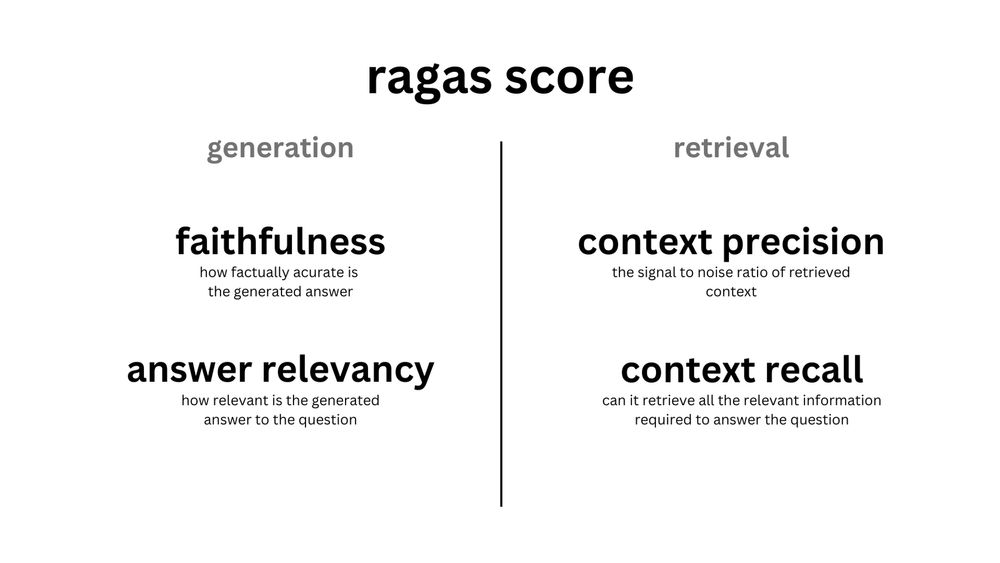


In [ ]:
from tqdm import tqdm

# Which questions? Exactly the ones Lab 3 samples. Lab 3 first keeps only the questions the
# generator itself scored 1.0, then draws lab_sample_size of them with the shared seed. Same
# filter, same size, same seed, so both labs measure the same questions. The first 60 characters
# of each are printed below so you can compare them with Lab 3's list.
# Size and seed come from the shared config, not from this cell. The size is large enough to see
# the pattern and small enough to finish inside the time box. The seed is fixed so that your
# numbers and your neighbour's are comparable.
N_QUESTIONS = SHARED['lab_sample_size']
quality_df = golden_df[golden_df['synthetic_input_quality'] == SHARED['quality_filter']]
sample_test_df = quality_df.sample(N_QUESTIONS, random_state=SHARED['random_state']).reset_index(drop=True)
print(f"answering {N_QUESTIONS} golden questions with {MODEL}")
for n, q in enumerate(sample_test_df['input'], start=1):
    print(f"{n:>2}. {q[:60]}")

output = []

def process_question(row):
    """Processes a single question and returns the required output format."""
    temp_info = {'question': row['input']}
    temp_info['ground_truth'] = row['expected_output']
    nodes = retriever.retrieve(row['input'])
    context_str = "\n\n".join([n.node.get_content() for n in nodes])
    messages_chat = [
                {"content": qa_template.format(context_str=context_str, query_str=row['input']), "role": "user"}
            ]

    # MODEL is the LiteLLM form from the shared config. Lab 2 uses the cheaper model on
    # purpose: it fires more calls per attendee than any other lab.
    response = completion(model=MODEL, messages=messages_chat, temperature=1, stream=False)
    response_text = response.choices[0].message.content
    temp_info['answer'] = response_text # Convert response object to string
    temp_info['contexts'] = [node.node.text for node in nodes]
    return temp_info


for _, row in tqdm(sample_test_df.iterrows(), total=sample_test_df.shape[0]):
    output.append(process_question(row))


sample_test_df = pd.DataFrame(output)

In [ ]:
# Five answers beside the golden answer. The retrieved contexts are long, so they are left
# out here; the next cell shows one row in full.
left_aligned(sample_test_df.sample(5)[['question', 'ground_truth', 'answer']])

In [ ]:
sample_test_df.head(1)

In [ ]:
# RAGAS needs to be told where to send BOTH its judge calls and its embedding calls.
# Passing only the judge leaves answer_relevancy on OpenAI's defaults, where it dies
# without an OpenAI key. Point both at OpenRouter.
_openrouter = dict(base_url="https://openrouter.ai/api/v1",
                   api_key=os.environ["OPENROUTER_API_KEY"])

# The judge model comes from the shared config, so every table in the room is scored by the
# same judge. The embedding line below keeps OpenRouter's unprefixed spelling: this path is
# LangChain with base_url set, not LiteLLM, so the 'openrouter/' prefix used elsewhere in
# this notebook would not resolve here.
ragas_judge = LangchainLLMWrapper(
    ChatOpenAI(model=SHARED['judge_model'], temperature=0, **_openrouter))
ragas_embeddings = LangchainEmbeddingsWrapper(
    OpenAIEmbeddings(model="openai/text-embedding-3-small", **_openrouter))

result = evaluate(
    Dataset.from_pandas(sample_test_df[['question', 'ground_truth', 'answer', 'contexts']]),
    metrics=[
        context_precision,
        faithfulness,
        answer_relevancy,
        context_recall,
    ],
    llm=ragas_judge,
    embeddings=ragas_embeddings,
)

# A judge call that hits a rate limit does not raise here, it comes back with no score, and
# the average is then quietly taken over whatever survived. Count them, so an average over
# four answers is never mistaken for an average over fifteen.
scores_df = result.to_pandas()
metric_cols = [c for c in scores_df.columns
               if c in ("context_precision", "faithfulness", "answer_relevancy", "context_recall")]
unscored = scores_df[metric_cols].isna().sum()
if unscored.any():
    print("Some judge calls came back without a score:")
    for metric, n in unscored[unscored > 0].items():
        print(f"  {metric}: {n} of {len(scores_df)} unscored, "
              f"so that average is over {len(scores_df) - n} questions.")
    print("Rerun the cell if you want a clean set. The scores below are still readable.")
else:
    print(f"Every metric scored all {len(scores_df)} questions.")

result

Given the small subset of testing examples, we can start to measure how well our system is doing. That being said, there are many ways for us to further evaluate the system as well as explore how to improve.

**What these four numbers are for.** They show how much a score moves between runs and between people. They are not a target to beat in the next lab. A baseline exists for this corpus, measured over six full runs of exactly this notebook (6 runs, 2026-10-20):

```
context_precision  0.60      faithfulness   0.68
answer_relevancy   0.89      context_recall 0.70
```

**Expect to land within about ±0.08 of each.** Generation runs at `temperature=1`, the sample is small, and the RAGAS judge is itself a model, so your numbers will not match to four decimal places and they are not supposed to. Across six runs no metric moved more than 0.08 from its mean, and that was context precision (0.53 to 0.66); answer relevancy and context recall stayed within 0.02. A result inside that band is the system working, not a bug. Run the scoring cell again, or compare with the person next to you: a gap smaller than the band is noise, not a difference between pipelines.

You should see roughly **468 chunks** indexed from the 137 data sheets, 256 pages in all. Lab 3 downloads a corpus of 452 chunks over the same documents. Both are correct: this notebook chunks the PDFs itself, and Lab 3 uses a corpus parsed separately with LlamaParse. Different parse, different chunk boundaries, same source material.

You will also see `LLM returned 1 generations instead of requested 3` repeated during scoring. `answer_relevancy` asks the judge to reverse-engineer three questions from each answer and OpenRouter returns one, so that metric scores on a single sample. It is harmless and the same for everyone. It did not make `answer_relevancy` the noisiest metric here: across six runs it was, with context recall, one of the two steadiest.

**Lab 3 makes its own comparison.** It does not reuse these numbers, and you do not need to carry them over. It compares naive retrieval against hybrid retrieval on the corpus parsed with LlamaParse, on the same questions you just ran here, scored by its own set of metrics, so the two retrievers are measured against each other in one place.

<!-- twin: dataset-specific -->

____
## LAB 2-C: Make your own test questions (about 30 minutes)

The golden set in 2-B was generated by a tool, and you only read a few of its questions. A test set you can trust is one a person has read. Here you build a small one from the hard pages you just inspected, review it, and use it to compare two retrievers.

1. **Generate** (about 10 minutes): ask the model for five questions per page, each with the passage that answers it.
2. **Review** (about 10 minutes): keep, fix or drop each question, and say why.
3. **Experiment** (about 10 minutes): score naive and hybrid retrieval on the questions you kept. No judge model is involved.
4. **Hold out**: tune on one half of the documents and report once on the other.

A useful test question records the evidence it needs: here, the quote that answers it and the page it sits on. A question that a program has checked is a development label, not gold.

### Step 1. Generate

By default the pages are the highest-scoring ones from your triage, one page from each of four different documents (any page you gave a verdict comes first). A page with almost no indexed text is skipped and the cell says so. To use any page of any document instead, replace `GEN_PAGES` in the cell with a list of `(file name, page number)` pairs; the example is in a comment.

There is one model call per page, with the same model as the rest of this lab. It is given the text this lab indexes for that page, the pypdf text, so a question inherits whatever pypdf got wrong. The prompt is short enough to read in the cell.

Then a program checks each quote: does at least 80% of it appear on the page? Questions whose quote does not are flagged **quote not found on the page**. That is a hint for your review, not a verdict. An automatic check like this gives you development labels, not gold: a quote can be on the page and still not answer the question.

In [ ]:
#@title Generate five questions per page (about 10 minutes)
# twin: dataset-specific
import re, unicodedata

# Does this quote really appear in the text? The same rule scores retrieval further down.
# Lowercase, strip markup and punctuation, then compare runs of words ("shingles").
SHINGLE = SHARED["retrieval_metrics"]["shingle_size"]
HIT_THRESHOLD = SHARED["retrieval_metrics"]["hit_threshold"]

def words_of(text):
    # Tags only, so a bare "< 50 g/L" stays text; NFKC turns a ligature glyph back into its letters.
    text = re.sub(r"</?[A-Za-z][A-Za-z0-9]*(?:\s[^<>]*)?/?>", " ", text)
    return re.sub(r"[^a-z0-9]+", " ", unicodedata.normalize("NFKC", text).lower()).split()

def share_of_quote_in(text, quote):
    """The share of the quote's 6-word shingles that also appear in the text (a short quote: 1 or 0)."""
    quote_words, text_words = words_of(quote), words_of(text)
    if len(quote_words) < SHINGLE:
        return float(" ".join(quote_words) in " ".join(text_words))
    shingles = lambda w: {tuple(w[i:i + SHINGLE]) for i in range(len(w) - SHINGLE + 1)}
    wanted = shingles(quote_words)
    return len(wanted & shingles(text_words)) / len(wanted)

def contains_quote(text, quote, share=HIT_THRESHOLD):
    return share_of_quote_in(text, quote) >= share

# Which pages? By default: one page from each of four different documents, taken from the
# pages you gave a verdict, then from the triage list. A page with almost no indexed text is
# skipped, because a question needs a passage to quote. To use your own pages, replace
# GEN_PAGES with any list of (file name, page number), for example
#   GEN_PAGES = [("3190_TDS_US.pdf", 1), ("970_TDS_US.pdf", 1)]
def default_pages(n_docs=4, min_chars=200):
    chosen = {}
    for doc, page_no in list(zip(page_verdicts["doc"], page_verdicts["page"])) + list(zip(flagged["doc"], flagged["page"])):
        if doc in chosen:
            continue
        if len(indexed_page_text(doc, int(page_no)).strip()) < min_chars:
            print(f"Skipping {doc} page {page_no}: this lab indexes almost no text for it, so a question has nothing to quote.")
            continue
        chosen[doc] = int(page_no)
        if len(chosen) == n_docs:
            break
    return list(chosen.items())

GEN_PAGES = default_pages()

# The whole prompt, short enough to read and change. The quote has to be copied word for word,
# because that quote is what we check the retrieved chunks against later.
GENERATE_PROMPT = """Below is the text of one page from a document.
Write 5 questions that a real person could type into a help desk search box and that this page answers.
For each question give the passage on the page that answers it, copied word for word.
Return a JSON object with one key, "questions": a list of 5 objects, each with the keys
"question", "quote" and "page" (the page number given below).

Document: {doc}
Page: {page}
Text of the page:
{text}"""

def generate_questions(doc, page_no):
    prompt = GENERATE_PROMPT.format(doc=doc, page=page_no, text=indexed_page_text(doc, page_no))
    reply = completion(model=MODEL, temperature=0, response_format={"type": "json_object"},
                       messages=[{"role": "user", "content": prompt}])
    try:  # models sometimes wrap JSON in a code fence, or return a bare list
        raw = re.sub(r"^```(?:json)?|```$", "", reply.choices[0].message.content.strip(), flags=re.M)
        data = json.loads(raw)
        items = data["questions"] if isinstance(data, dict) else data
        return [dict(doc=doc, page=page_no, question=str(q["question"]).strip(), quote=str(q["quote"]).strip())
                for q in items if isinstance(q, dict) and q.get("question") and q.get("quote")]
    except Exception:
        print(f"The reply for {doc} page {page_no} was not JSON we could read. Run this cell again.")
        return []

with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:
    batches = list(pool.map(lambda p: generate_questions(*p), GEN_PAGES))
generated = pd.DataFrame([row for batch in batches for row in batch], columns=["doc", "page", "question", "quote"])

# The automatic check: is the quote on the page the model was given?
generated["quote_check"] = [
    "ok" if contains_quote(indexed_page_text(r.doc, r.page), r.quote, share=0.8) else "quote not found on the page"
    for r in generated.itertuples()]

print(f"{len(generated)} questions from {len(GEN_PAGES)} pages. "
      f"{(generated['quote_check'] != 'ok').sum()} have a quote that was not found on the page.")
pd.set_option("display.max_colwidth", 90)
left_aligned(generated[["doc", "page", "question", "quote_check"]])

### Step 2. Review

Read every question and its quote. Would a person type this? Does the quote really answer it? Record your decisions in the two dicts in the next cell: `VERDICTS` marks a row keep, fix or drop with a reason, and `FIXES` gives the rewritten text of a question you want to fix. Both start empty, which keeps every question as generated, so the cell runs as it is. The counts print beside the golden set's style counts from 2-B, so you can compare your questions with the generator's.

In [ ]:
#@title Review: keep, fix or drop each question
# twin: dataset-specific
# Read the table above and the quotes below, then record your decisions in these two dicts.
# Both start empty, so everything is kept as generated. The number is the row number on the left.
#   VERDICTS = {3: ("drop", "answer is not on the page")}      # "keep", "fix" or "drop", and why
#   FIXES    = {7: "How long do I wait before recoating?"}   # your rewritten question
VERDICTS = {}
FIXES = {}

reviewed = generated.assign(original_question=generated["question"], verdict="keep", reason="")
for row_number, (verdict, reason) in VERDICTS.items():
    if row_number in reviewed.index and verdict in ("keep", "fix", "drop"):
        reviewed.loc[row_number, ["verdict", "reason"]] = [verdict, reason]
    else:
        print(f"Ignored VERDICTS entry {row_number}: use a row number from the table and keep, fix or drop.")
for row_number, new_question in FIXES.items():
    if row_number in reviewed.index:
        reviewed.loc[row_number, "question"] = new_question
        if reviewed.loc[row_number, "verdict"] != "drop":
            reviewed.loc[row_number, "verdict"] = "fix"
    else:
        print(f"Ignored FIXES entry {row_number}: there is no such row.")

counts = reviewed["verdict"].value_counts().reindex(["keep", "fix", "drop"], fill_value=0)
print("Your review of the questions you generated:")
print(counts.to_string())
print("\nFor comparison, the styles of the golden set's questions (from the cell above):")
print(style_counts.to_string())
print("\nThe generator wrote those styles on request. Which of yours would a real user type?")

kept_questions = reviewed[reviewed["verdict"] != "drop"]
pd.set_option("display.max_colwidth", 200)
left_aligned(reviewed[["page", "question", "quote", "quote_check", "verdict", "reason"]])

### Step 3. Experiment

Two retrievers, the same chunks you indexed in 2-A:

* **naive**: dense retrieval, the retriever from 2-A. It ranks chunks by embedding similarity alone.
* **hybrid**: the dense ranking and a BM25 keyword ranking fused by reciprocal rank, built exactly as Lab 3 builds it. Lab 3 explains the fusion.

Each is scored on your kept questions with three numbers, no judge needed:

* **doc@5**: some chunk in the top 5 comes from the PDF the question was written from. Right document, wrong place still counts.
* **hit@5**: some chunk in the top 5 contains the supporting quote. A chunk contains the quote when at least `hit_threshold` of the quote's `shingle_size`-word runs appear in the chunk, after lowercasing and stripping markup and punctuation. A quote shorter than `shingle_size` words counts when its text appears inside the chunk. Both settings come from the shared config, the same ones Lab 3 reads.
* **MRR**: 1 divided by the rank of the first chunk that contains the quote, or 0 if none of the top 5 does, averaged over the questions.

With a handful of questions the gap between two retrievers is often one or two questions. Read the table as a first look. Twenty questions from four pages can go either way, and naive retrieval may well come out ahead of hybrid here. That is a result about this small set, not a verdict on hybrid search: Lab 3 compares the retrievers on the golden set.

In [ ]:
#@title Experiment: naive against hybrid retrieval on your kept questions
import logging, nest_asyncio, Stemmer
from llama_index.core.llms import MockLLM
from llama_index.core.retrievers import QueryFusionRetriever
from llama_index.retrievers.bm25 import BM25Retriever

logging.getLogger("bm25s").setLevel(logging.WARNING)   # the BM25 library logs every index it builds
nest_asyncio.apply()  # lets the fusion retriever run its two searches together inside a notebook

TOP_K = SHARED["similarity_top_k"]

# naive: the dense retriever from 2-A. keyword: BM25 over the same chunks you indexed.
# hybrid: fuse the two ranked lists by reciprocal rank, built as Lab 3 builds it.
# num_queries=1 means no model is asked to rewrite the question. The retriever still wants an
# llm object, so it gets one that cannot be called.
bm25_retriever = BM25Retriever.from_defaults(nodes=index_nodes, similarity_top_k=TOP_K,
                                             stemmer=Stemmer.Stemmer("english"), language="english")
hybrid_retriever = QueryFusionRetriever([retriever, bm25_retriever], mode="reciprocal_rerank", num_queries=1,
                                        similarity_top_k=TOP_K, use_async=True, llm=MockLLM())
engines = {"naive (dense)": retriever, "hybrid (dense + BM25)": hybrid_retriever}

def score_retrieval(engine, questions):
    """Per question: doc@k, hit@k and reciprocal rank. The only model calls are query embeddings."""
    rows = []
    for q in questions.itertuples():
        top = engine.retrieve(q.question)[:TOP_K]
        holds_quote = [contains_quote(n.node.get_content(), q.quote) for n in top]
        first = holds_quote.index(True) + 1 if any(holds_quote) else None   # rank of the first chunk with the quote
        rows.append(dict(doc=q.doc,
                         doc_hit=any(n.node.metadata["file_name"] == q.doc for n in top),
                         hit=first is not None,
                         rr=1 / first if first else 0.0))
    return pd.DataFrame(rows, index=questions.index)

def summarise(per_question):
    return pd.DataFrame({f"doc@{TOP_K}": per_question.groupby("engine")["doc_hit"].mean(),
                         f"hit@{TOP_K}": per_question.groupby("engine")["hit"].mean(),
                         "MRR": per_question.groupby("engine")["rr"].mean(),
                         "questions": per_question.groupby("engine").size()}).round(3)

per_question = pd.concat([score_retrieval(engine, kept_questions).assign(engine=name)
                          for name, engine in engines.items()])
print(f"Scored {len(kept_questions)} kept questions on {len(engines)} retrievers (top {TOP_K} chunks each).")
summarise(per_question)

### Step 4. Hold out

The next cell splits your kept questions **by document**, not by question. Questions written from the same page are near copies of each other, and a split by question would let the half you tune on leak into the half you report on. It picks the retriever that wins on the tune half, then shows that one retriever on the held-out half.

Look at the held-out half once. Every time you peek at it and change something, it becomes a second tuning set, and the number you report no longer says how the choice will do on questions you have not seen.

**Reading a big drop.** The held-out score can be far lower than the tune score. That is the lesson working, not a bug: questions written from one or two documents do not predict how the others will do, which is why you report on the half you did not tune on.

In [ ]:
#@title Hold out: tune on one half of the documents, report once on the other
# Split by document, not by question. Questions written from the same page are near copies of
# each other, and a split by question would let the tuning half leak into the held-out half.
documents_in_set = sorted(kept_questions["doc"].unique())
tune_docs, held_docs = documents_in_set[0::2], documents_in_set[1::2]
print(f"Tune half: {len(tune_docs)} document(s). Held-out half: {len(held_docs)} document(s).")

if not held_docs:
    print("Your kept questions come from a single document, so there is nothing to hold out. "
          "Generate from pages of at least two documents and run the cells again.")
else:
    tune = summarise(per_question[per_question["doc"].isin(tune_docs)]).reindex(list(engines))   # naive first
    print("\nTune half, both engines:")
    display(tune)
    # Pick on MRR, then hit@k. A tie goes to the simpler engine, naive.
    winner = tune.sort_values(["MRR", f"hit@{TOP_K}"], ascending=False, kind="stable").index[0]
    print(f"Winner on the tune half: {winner}. Now the held-out half, once:")
    display(summarise(per_question[per_question["doc"].isin(held_docs) & (per_question["engine"] == winner)]))

---
**STOP** - end of LAB 2-C

### What you should have seen

* **How many chunks the index holds.** The data ingestion cell printed 468 chunks from 256 pages (1 run, 2026-10-20). The exact count depends on the chunk size, the text pypdf extracts and the file details counted into each chunk's size, so a different setup can move it by a few.

* **The hardest pages in the corpus, and why each was flagged.** The triage scored every page with PyMuPDF only. Its ten highest-scoring pages (1 run, 2026-10-20), at most four per document and three alike:
    * `982_TDS_US.pdf` page 1, score 6: no text layer (scan)
    * `2190_TDS_US.pdf` page 1, score 5: tables found; merged header cells; wrapped cell (4+ lines)
    * `3190_TDS_US.pdf` page 1, score 5: tables found; merged header cells; wrapped cell (4+ lines)
    * `970_TDS_US.pdf` page 1, score 4: tables found; wrapped cell (4+ lines)
    * `BC10_TDS_US.pdf` page 1, score 4: tables found; merged header cells
    * `BC20_TDS_US.pdf` page 1, score 4: tables found; merged header cells
    * `BP40_TDS_US.pdf` page 1, score 4: tables found; merged header cells
    * `10007_TDS_US.pdf` page 1, score 2: tables found; merged header cells
    * `1000_TDS_US.pdf` page 1, score 2: tables found; merged header cells
    * `1004_TDS_US.pdf` page 1, score 2: tables found; merged header cells

* **What the page images showed.** Four of the ten, looked at beside their text (1 run, 2026-10-20). Sheet 982 is a clean, readable data sheet to the eye, but both PyMuPDF and pypdf return no text for it at all, so nothing on that sheet can be retrieved and no question can be written from it. On sheet 3190 (2190 carries the same table) the compliance box, a column of regulations beside a column of YES, comes out as a run of labels and YES values that only line order ties together, and the product numbers listed against MPI sit apart from the MPI label. On sheet 970 the mixing table's container sizes and pouch counts arrive interleaved, so "1 GALLON" and "1 pouch" pair up only by line order. On BC10 the coverage chart prints three widths in one line and then three values that sit on a diagonal, so the text no longer says which width each value belongs to. Every one of these reads as plausible text. Only the page image shows what the text lost.

* **Four RAGAS scores, inside a stated band.** context_precision, faithfulness, answer_relevancy and context_recall should each land within about ±0.08 of the baseline in the cell above (6 runs, 2026-10-20). Context precision moves the most.

* **A warning that is expected.** `LLM returned 1 generations instead of requested 3` repeats during scoring. It is harmless and the same for everyone.

* **Your own test set.** Lab 2-C ends with your kept, fixed and dropped counts, and one retriever reported once on a held-out half. Your numbers are your own: a handful of questions, split by document, so compare the shape of the result with your neighbour's rather than the third decimal.


<!-- twin: dataset-specific -->